# Cirrhosis full pipeline

One self-contained notebook covering the complete workflow: raw data audit, exploration,
cleaning, preprocessing, model comparison, calibration, final selection and submission.

Every helper function is defined in the cells below. No project modules are imported.

In [1]:
import json
import time
import warnings
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SOURCE_DIR = ROOT / "data" / "raw" / "multiclassificationtask (1)"
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
FIGURES_DIR = MODELS_DIR / "figures"
REPORTS_DIR = ROOT / "reports"
SUBMISSION_PATH = ROOT / "submission.csv"
PIPELINE_PATH = MODELS_DIR / "final_pipeline.joblib"
METADATA_PATH = MODELS_DIR / "metadata.json"

for folder in (PROCESSED_DIR, FIGURES_DIR, REPORTS_DIR / "data_quality",
               REPORTS_DIR / "cleaning", REPORTS_DIR / "experiments",
               REPORTS_DIR / "final_evaluation"):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "Status"
ID_COLUMN = "id"
CLASS_LABELS = ["C", "CL", "D"]
PROB_COLUMNS = [f"Status_{label}" for label in CLASS_LABELS]
RAW_NUMERIC = ["N_Days", "Age", "Bilirubin", "Cholesterol", "Albumin", "Copper",
               "Alk_Phos", "SGOT", "Tryglicerides", "Platelets", "Prothrombin", "Stage"]
RAW_CATEGORICAL = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema"]
RAW_FEATURES = RAW_NUMERIC + RAW_CATEGORICAL
CORE_NUMERIC = ["Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos",
                "SGOT", "Tryglicerides", "Platelets", "Prothrombin", "Stage"]
SKEWED = ["Bilirubin", "Cholesterol", "Copper", "Alk_Phos", "SGOT", "Tryglicerides"]
OUTCOME_TEXT = {"C": "alive at end of study", "CL": "liver transplant", "D": "death during study"}
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "figure.autolayout": True})
print("environment ready", ROOT)

environment ready /home/sabina/portfolio/cirrhosis


## raw data audit

Load the immutable source files, profile their schemas and record integrity findings.

In [2]:
def load_raw():
    # load the three source files
    train = pd.read_csv(SOURCE_DIR / "train.csv")
    test = pd.read_csv(SOURCE_DIR / "test.csv")
    template = pd.read_csv(SOURCE_DIR / "sample_submission.csv")
    return train, test, template


def schema_summary(frame):
    # compact dtype and missingness table
    rows = []
    for column in frame.columns:
        series = frame[column]
        missing = int(series.isna().sum())
        rows.append({"column": column, "dtype": str(series.dtype),
                     "missing": missing,
                     "missing_pct": round(100 * missing / len(series), 2),
                     "n_unique": int(series.nunique(dropna=True))})
    return pd.DataFrame(rows)


def integrity_audit(train, test):
    # record structural findings without changing inputs
    invalid = train[~train[TARGET].isin(CLASS_LABELS)]
    age_years = train["Age"] / 365.25
    return {
        "train_rows": len(train),
        "test_rows": len(test),
        "duplicate_rows": int(train.duplicated().sum()),
        "id_overlap": len(set(train[ID_COLUMN]) & set(test[ID_COLUMN])),
        "invalid_label_rows": invalid[ID_COLUMN].tolist(),
        "age_below_18": int((age_years < 18).sum()),
        "age_above_100": int((age_years > 100).sum()),
        "n_days_median_by_status": train.groupby(TARGET)["N_Days"].median().round(1).to_dict(),
        "class_counts": train[TARGET].value_counts().to_dict(),
    }


train, test, template = load_raw()
print("shapes:", train.shape, test.shape, template.shape)
schema_train = schema_summary(train)
print(schema_train.to_string(index=False))
schema_train.to_csv(REPORTS_DIR / "data_quality" / "schema_train.csv", index=False)
schema_summary(test).to_csv(REPORTS_DIR / "data_quality" / "schema_test.csv", index=False)

shapes: (15000, 20) (10000, 19) (10000, 4)
       column   dtype  missing  missing_pct  n_unique
           id   int64        0         0.00     15000
       N_Days float64        0         0.00       553
         Drug     str     6506        43.37         2
          Age float64        0         0.00       391
          Sex     str        0         0.00         2
      Ascites     str     6498        43.32         2
 Hepatomegaly     str     6508        43.39         2
      Spiders     str     6509        43.39         2
        Edema     str        0         0.00         3
    Bilirubin float64        0         0.00       117
  Cholesterol float64     8299        55.33       218
      Albumin float64        0         0.00       163
       Copper float64     6601        44.01       174
     Alk_Phos float64     6512        43.41       381
         SGOT float64     6514        43.43       201
Tryglicerides float64     8334        55.56       158
    Platelets float64      564         

train_rows: 15000
test_rows: 10000
duplicate_rows: 0
id_overlap: 0
invalid_label_rows: [13789]
age_below_18: 12
age_above_100: 2
n_days_median_by_status: {'C': 2170.0, 'CL': 1447.0, 'D': 1067.0, 'Y': 4127.0}
class_counts: {'C': 10053, 'D': 4565, 'CL': 381, 'Y': 1}


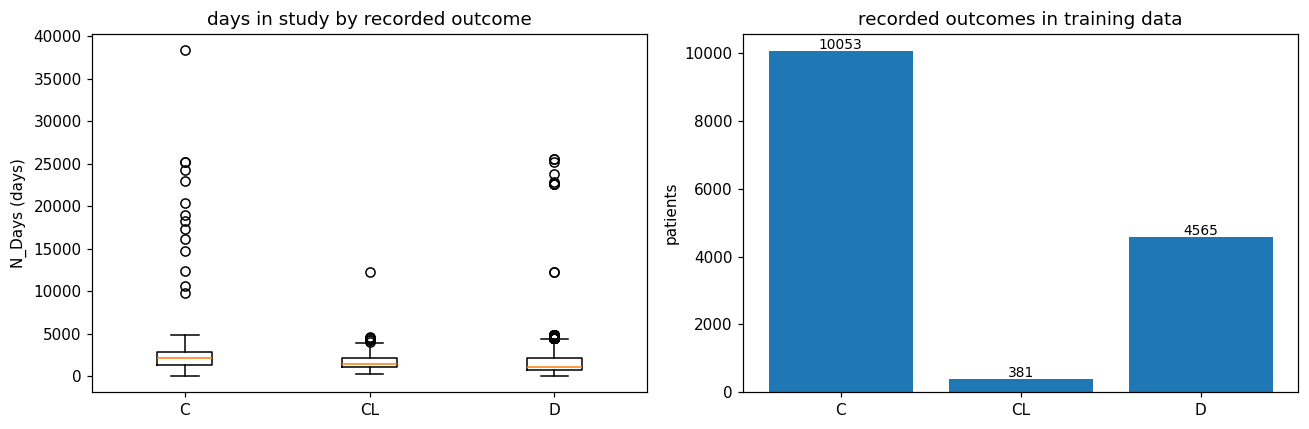

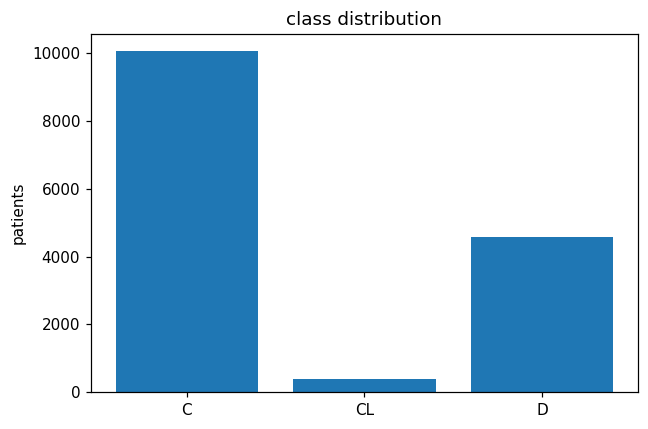

In [3]:
audit = integrity_audit(train, test)
with (REPORTS_DIR / "data_quality" / "integrity_audit.json").open("w") as handle:
    json.dump(audit, handle, indent=2, default=str)
for key, value in audit.items():
    print(f"{key}: {value}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
groups = [train.loc[train[TARGET] == label, "N_Days"].values for label in CLASS_LABELS]
axes[0].boxplot(groups, labels=CLASS_LABELS)
axes[0].set_title("days in study by recorded outcome")
axes[0].set_ylabel("N_Days (days)")
counts = train[TARGET].value_counts().reindex(CLASS_LABELS)
axes[1].bar(CLASS_LABELS, counts.values)
axes[1].set_title("recorded outcomes in training data")
axes[1].set_ylabel("patients")
for i, value in enumerate(counts.values):
    axes[1].text(i, value + 60, str(value), ha="center", fontsize=9)
fig.savefig(FIGURES_DIR / "01_ndays_by_status.png", bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(CLASS_LABELS, counts.values)
ax.set_title("class distribution")
ax.set_ylabel("patients")
fig.savefig(FIGURES_DIR / "01_class_distribution.png", bbox_inches="tight")
plt.show()

## exploratory analysis

Univariate, missingness, correlation and outcome charts. Matplotlib is used for every plot.

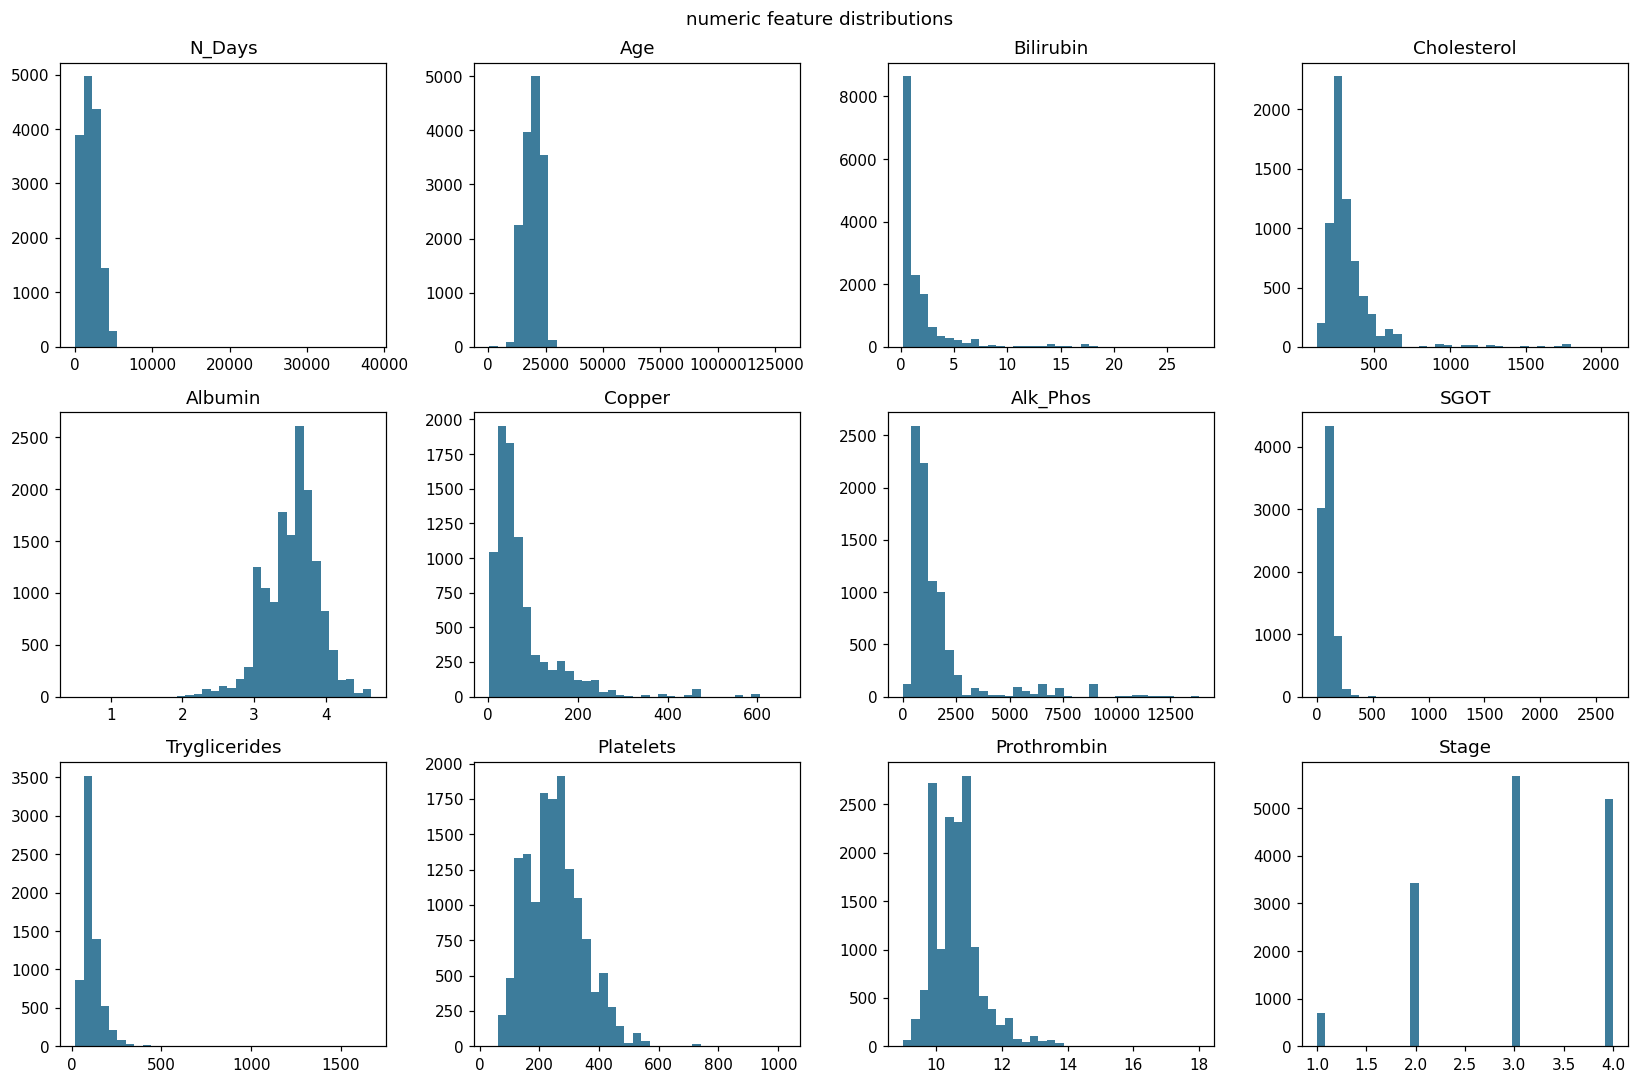

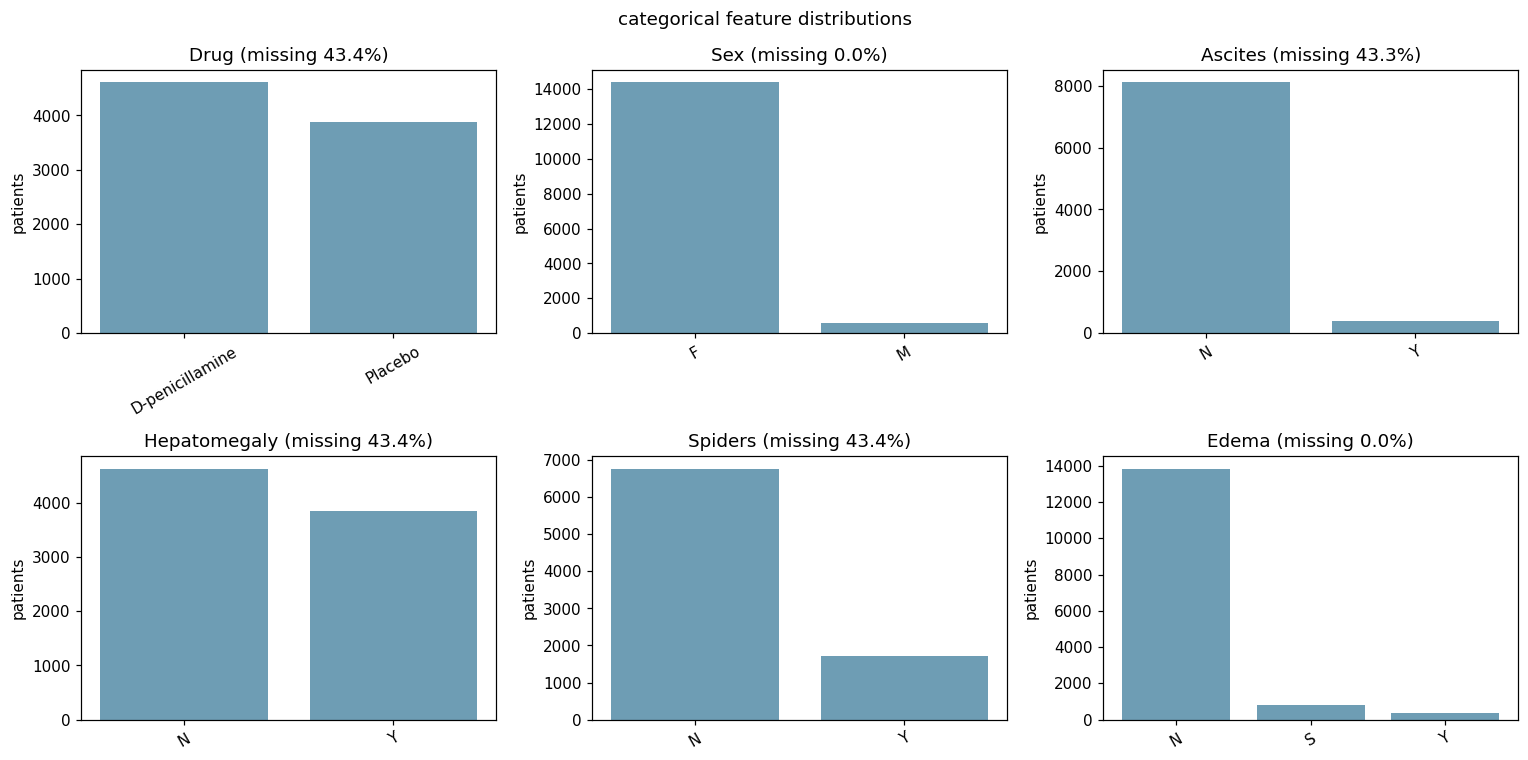

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, column in zip(axes.ravel(), RAW_NUMERIC):
    ax.hist(train[column].dropna(), bins=35, color="#3D7C9B")
    ax.set_title(column)
    ax.set_xlabel("")
fig.suptitle("numeric feature distributions")
fig.savefig(FIGURES_DIR / "02_numeric_distributions.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, column in zip(axes.ravel(), RAW_CATEGORICAL):
    values = train[column].astype(str).value_counts()
    ax.bar(values.index, values.values, color="#6E9DB4")
    ax.set_title(f"{column} (missing {train[column].isna().mean():.1%})")
    ax.set_ylabel("patients")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("categorical feature distributions")
fig.savefig(FIGURES_DIR / "02_categorical_distributions.png", bbox_inches="tight")
plt.show()

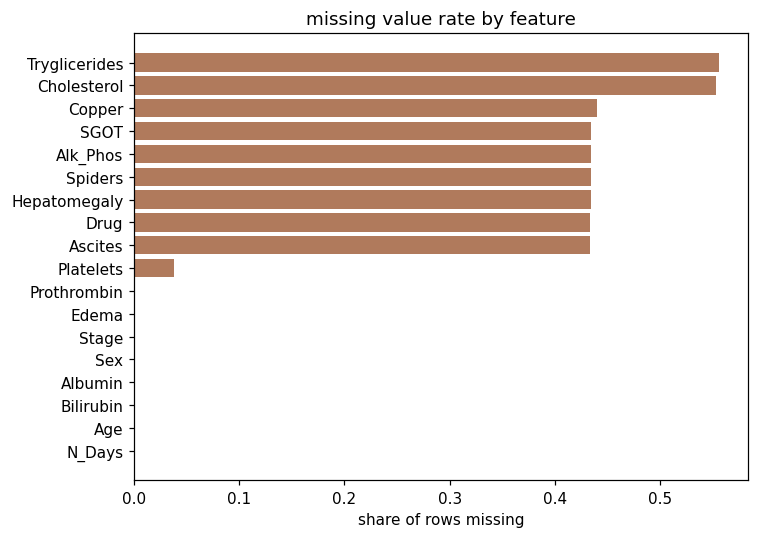

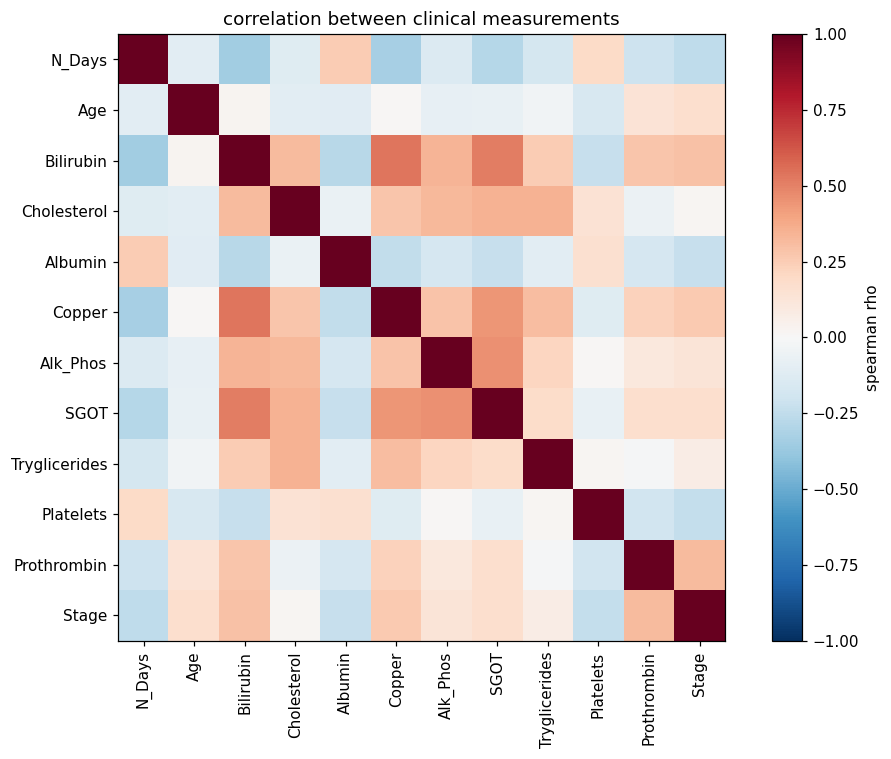

In [5]:
missing = train[RAW_FEATURES].isna().mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(missing.index, missing.values, color="#B07A5C")
ax.set_title("missing value rate by feature")
ax.set_xlabel("share of rows missing")
fig.savefig(FIGURES_DIR / "02_missingness.png", bbox_inches="tight")
plt.show()

corr = train[RAW_NUMERIC].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(image, ax=ax, label="spearman rho")
ax.set_title("correlation between clinical measurements")
fig.savefig(FIGURES_DIR / "02_correlation.png", bbox_inches="tight")
plt.show()

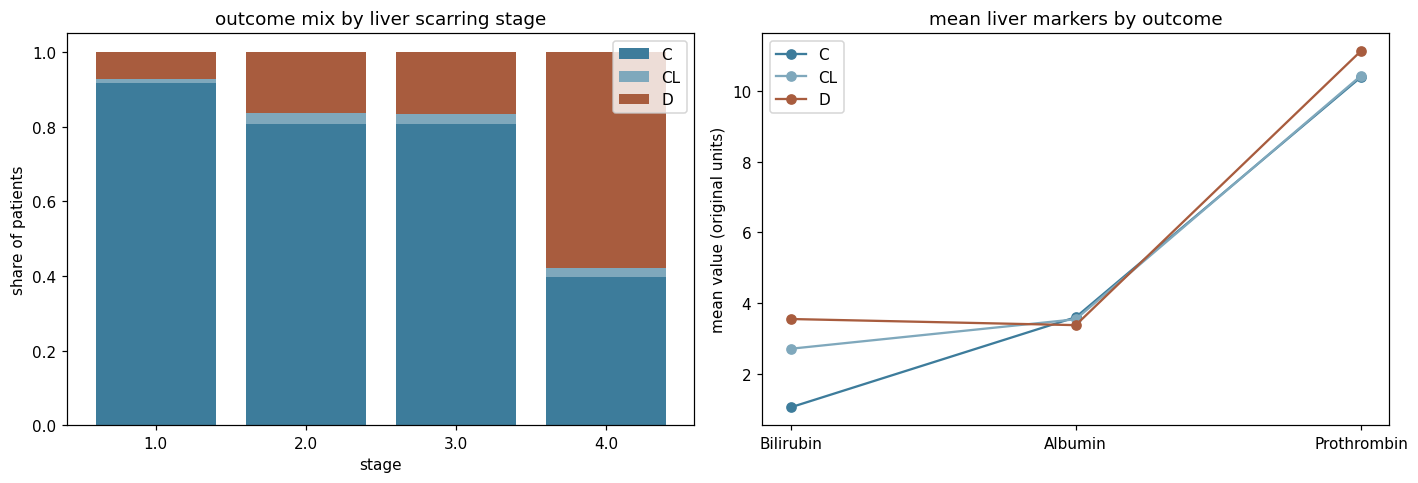

In [6]:
stage_mix = pd.crosstab(train["Stage"], train[TARGET], normalize="index").reindex(columns=CLASS_LABELS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bottom = np.zeros(len(stage_mix))
for label, colour in zip(CLASS_LABELS, ["#3D7C9B", "#7FA8BC", "#A85C3E"]):
    axes[0].bar(stage_mix.index.astype(str), stage_mix[label], bottom=bottom, label=label, color=colour)
    bottom += stage_mix[label].values
axes[0].set_title("outcome mix by liver scarring stage")
axes[0].set_xlabel("stage")
axes[0].set_ylabel("share of patients")
axes[0].legend()
markers = ["Bilirubin", "Albumin", "Prothrombin"]
for label, colour in zip(CLASS_LABELS, ["#3D7C9B", "#7FA8BC", "#A85C3E"]):
    means = [train.loc[train[TARGET] == label, column].mean() for column in markers]
    axes[1].plot(markers, means, marker="o", label=label, color=colour)
axes[1].set_title("mean liver markers by outcome")
axes[1].set_ylabel("mean value (original units)")
axes[1].legend()
fig.savefig(FIGURES_DIR / "02_target_relationships.png", bbox_inches="tight")
plt.show()

## cleaning, splitting and preprocessing

Remove the invalid label, flag implausible ages, then create a stratified holdout.
Preprocessing statistics are learned from training rows only.

In [7]:
def clean_training_data(frame):
    # drop invalid labels and clip implausible ages
    clean = frame[frame[TARGET].isin(CLASS_LABELS)].copy()
    age_years = clean["Age"] / 365.25
    bad_age = (age_years < 18) | (age_years > 100)
    clean["age_imputed_flag"] = bad_age.astype(int)
    clean["Age"] = age_years.clip(18, 100) * 365.25
    audit_table = pd.DataFrame([
        {"check": "total records", "before": len(frame), "after": len(clean)},
        {"check": "missing values", "before": int(frame.isna().sum().sum()),
         "after": int(clean.isna().sum().sum())},
        {"check": "invalid labels", "before": int((~frame[TARGET].isin(CLASS_LABELS)).sum()), "after": 0},
        {"check": "out of range ages", "before": int(bad_age.sum()), "after": int(bad_age.sum())},
        {"check": "retained percent", "before": 100.0,
         "after": round(100 * len(clean) / len(frame), 4)},
    ])
    return clean, audit_table


def feature_matrix(frame):
    # keep only columns used by the model
    return frame[RAW_FEATURES].copy()


clean, audit_table = clean_training_data(train)
print(audit_table.to_string(index=False))
audit_table.to_csv(REPORTS_DIR / "cleaning" / "before_after_audit.csv", index=False)
assert set(clean[TARGET]) == set(CLASS_LABELS)

            check  before      after
    total records 15000.0 14999.0000
   missing values 62861.0 62861.0000
   invalid labels     1.0     0.0000
out of range ages    14.0    14.0000
 retained percent   100.0    99.9933


In [8]:
X = feature_matrix(clean)
y_text = clean[TARGET]
Xtr, Xv, ytr_text, yv_text = train_test_split(
    X, y_text, test_size=0.2, stratify=y_text, random_state=SEED)
code_map = {label: i for i, label in enumerate(CLASS_LABELS)}
ytr = ytr_text.map(code_map).astype(int)
yv = yv_text.map(code_map).astype(int)

train_out = Xtr.copy()
train_out[ID_COLUMN] = clean.loc[Xtr.index, ID_COLUMN].to_numpy()
train_out[TARGET] = ytr_text
val_out = Xv.copy()
val_out[ID_COLUMN] = clean.loc[Xv.index, ID_COLUMN].to_numpy()
val_out[TARGET] = yv_text
train_out.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_out.to_csv(PROCESSED_DIR / "val.csv", index=False)
print("train split", Xtr.shape, "validation split", Xv.shape)
print("class balance", ytr_text.value_counts(normalize=True).round(3).to_dict())

train split (11999, 18) validation split (3000, 18)
class balance {'C': 0.67, 'D': 0.304, 'CL': 0.025}


## feature engineering and preprocessing

Engineering is expressed with scikit-learn and NumPy built-ins so the saved pipeline
can be reloaded by any process. No locally defined classes are embedded in the pickle.

In [9]:
def feature_contract(include_n_days=True):
    # describe the engineered feature groups
    numeric = (["N_Days"] if include_n_days else []) + CORE_NUMERIC
    numeric += ["Age_years", "missing_count"] + [f"log_{c}" for c in SKEWED]
    return numeric, list(RAW_CATEGORICAL)


def numeric_steps():
    # median impute with missing indicators, then scale
    return Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])


def build_preprocessor(include_n_days=True):
    # train-only columns transformer
    missing_cols = RAW_NUMERIC if include_n_days else [c for c in RAW_NUMERIC if c != "N_Days"]
    parts = [
        ("core", numeric_steps(), CORE_NUMERIC),
        ("age", Pipeline([
            ("years", FunctionTransformer(func=partial(np.multiply, 1 / 365.25), validate=False)),
            ("clip", FunctionTransformer(func=np.clip, kw_args={"a_min": 18, "a_max": 100}, validate=False)),
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), ["Age"]),
        ("missing", Pipeline([
            ("flag", FunctionTransformer(func=np.isnan, validate=False)),
            ("count", FunctionTransformer(func=partial(np.sum, axis=1), validate=False)),
            ("shape", FunctionTransformer(func=np.atleast_2d, validate=False)),
            ("column", FunctionTransformer(func=np.transpose, validate=False)),
            ("scale", StandardScaler()),
        ]), missing_cols),
        ("logs", Pipeline([
            ("log", FunctionTransformer(func=np.log1p, validate=False)),
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), SKEWED),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), RAW_CATEGORICAL),
    ]
    if include_n_days:
        parts.append(("study_days", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), ["N_Days"]))
    return ColumnTransformer(parts, remainder="drop")


def make_pipeline(model, include_n_days=True):
    # one object for cross validation and serving
    return Pipeline([
        ("preprocessor", build_preprocessor(include_n_days)),
        ("classifier", model),
    ])


numeric_cols, categorical_cols = feature_contract(True)
print("engineered numeric columns:", len(numeric_cols))
print("categorical columns:", categorical_cols)
example = make_pipeline(LogisticRegression(max_iter=300), True)
example.fit(Xtr, ytr)
transformed = example.named_steps["preprocessor"].transform(Xtr)
print("transformed shape:", transformed.shape, "finite:", bool(np.isfinite(transformed).all()))

engineered numeric columns: 19
categorical columns: ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']


transformed shape: (11999, 39) finite: True


## candidate models and cross validation

Nine classifiers are compared with identical folds and preprocessing.
Log loss is the primary metric.

In [10]:
def get_candidates(seed=SEED):
    # model zoo
    return {
        "DummyPrior": DummyClassifier(strategy="prior"),
        "LogisticRegression": LogisticRegression(max_iter=2000, C=1.0, random_state=seed),
        "DecisionTree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "ExtraTrees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=350, learning_rate=0.05, max_depth=4,
                                 subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
                                 eval_metric="mlogloss", n_jobs=-1, random_state=seed),
        "LightGBM": LGBMClassifier(n_estimators=350, learning_rate=0.05, num_leaves=15,
                                   min_child_samples=30, reg_lambda=1.0, verbosity=-1,
                                   n_jobs=-1, random_state=seed),
        "CatBoost": CatBoostClassifier(iterations=350, learning_rate=0.05, depth=5,
                                       l2_leaf_reg=3.0, loss_function="MultiClass",
                                       verbose=False, allow_writing_files=False,
                                       thread_count=-1, random_seed=seed),
    }


def tuning_spaces(seed=SEED):
    # small search grids
    return {
        "LogisticRegression": {"classifier__C": [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]},
        "HistGradientBoosting": {
            "classifier__max_iter": [200, 350, 500],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__l2_regularization": [0.0, 1.0, 5.0],
        },
        "XGBoost": {
            "classifier__n_estimators": [200, 350, 500],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__max_depth": [3, 4, 5, 6],
            "classifier__subsample": [0.7, 0.85, 1.0],
            "classifier__reg_lambda": [0.5, 1.0, 5.0],
        },
        "LightGBM": {
            "classifier__n_estimators": [200, 350, 500],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__num_leaves": [7, 15, 31],
            "classifier__min_child_samples": [20, 30, 50],
        },
        "CatBoost": {
            "classifier__iterations": [200, 350, 500],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__depth": [4, 5, 6],
            "classifier__l2_leaf_reg": [1.0, 3.0, 8.0],
        },
    }


def score_predictions(y_true, proba, classes=CLASS_LABELS):
    # integer codes are mapped back to outcome names
    labels = np.asarray([classes[int(value)] if isinstance(value, (int, np.integer)) else value
                         for value in y_true])
    predicted = np.asarray(classes)[np.argmax(proba, axis=1)]
    return {
        "log_loss": float(log_loss(labels, proba, labels=classes)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "f1_macro": float(f1_score(labels, predicted, average="macro")),
    }


def benchmark(X, y, candidates, include_n_days=True, n_splits=5, seed=SEED):
    # out of fold benchmark
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rows, oof = [], {}
    for name, estimator in candidates.items():
        start = time.perf_counter()
        proba = cross_val_predict(make_pipeline(estimator, include_n_days), X, y,
                                  cv=cv, method="predict_proba", n_jobs=1)
        scores = score_predictions(y, proba)
        rows.append({"model": name, "include_n_days": include_n_days,
                     "log_loss": scores["log_loss"], "accuracy": scores["accuracy"],
                     "f1_macro": scores["f1_macro"],
                     "fit_seconds": round(time.perf_counter() - start, 2)})
        oof[name] = proba
    table = pd.DataFrame(rows).sort_values("log_loss").reset_index(drop=True)
    return table, oof


def tune_candidate(X, y, name, include_n_days=True, seed=SEED):
    # randomized search scored by log loss
    space = tuning_spaces(seed).get(name)
    if not space:
        raise ValueError(f"no tuning space for {name}")
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    search = RandomizedSearchCV(make_pipeline(get_candidates(seed)[name], include_n_days),
                                space, n_iter=8, scoring="neg_log_loss", cv=cv,
                                random_state=seed, n_jobs=1, refit=True, error_score="raise")
    search.fit(X, y)
    return clone(search.best_estimator_), search.best_params_, float(-search.best_score_)


def calibrate(estimator, X, y, method="sigmoid", seed=SEED):
    # cross fitted probability calibration
    calibrated = CalibratedClassifierCV(estimator, method=method,
                                        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=seed))
    calibrated.fit(X, y)
    return calibrated

               model  include_n_days  log_loss  accuracy  f1_macro  fit_seconds
             XGBoost            True  0.382005  0.854321  0.614033         7.93
            LightGBM            True  0.387592  0.854238  0.625839        12.44
            CatBoost            True  0.396384  0.849654  0.581676         6.77
        RandomForest            True  0.408726  0.846987  0.555224         5.55
HistGradientBoosting            True  0.431856  0.848821  0.612092        15.89
  LogisticRegression            True  0.444303  0.832986  0.553294         5.95
          ExtraTrees            True  0.457397  0.829069  0.534733         3.65
        DecisionTree            True  0.497105  0.832403  0.556894         0.59
          DummyPrior            True  0.723581  0.670223  0.267518         0.42


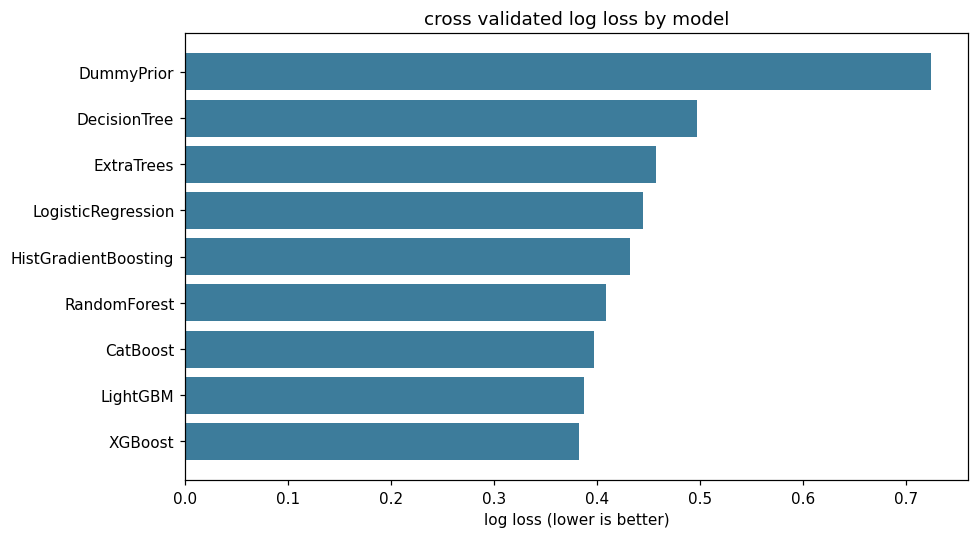

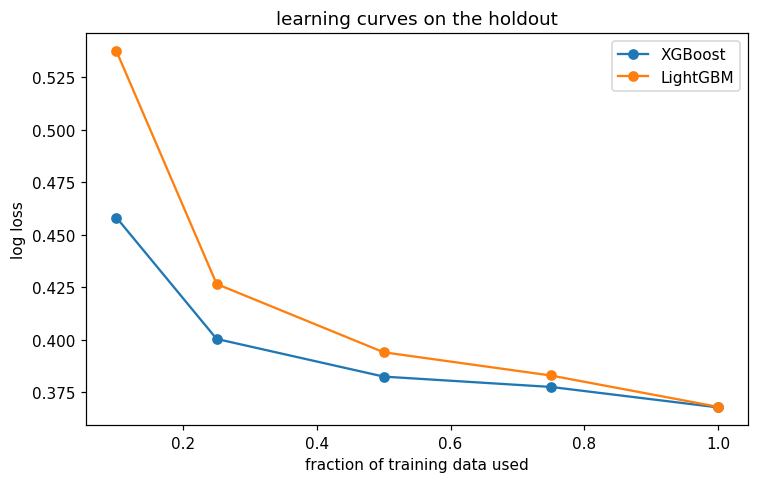

In [11]:
candidates = get_candidates()
leaderboard, oof = benchmark(Xtr, ytr, candidates)
leaderboard.to_csv(MODELS_DIR / "leaderboard.csv", index=False)
oof_columns = {}
for name, proba in oof.items():
    for i, label in enumerate(CLASS_LABELS):
        oof_columns[f"{name}_{label}"] = proba[:, i]
pd.DataFrame(oof_columns, index=ytr.index).to_csv(MODELS_DIR / "oof_predictions.csv", index=False)
print(leaderboard.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ordered = leaderboard.sort_values("log_loss")
ax.barh(ordered["model"], ordered["log_loss"], color="#3D7C9B")
ax.set_title("cross validated log loss by model")
ax.set_xlabel("log loss (lower is better)")
fig.savefig(FIGURES_DIR / "04_cv_logloss.png", bbox_inches="tight")
plt.show()

top_models = [name for name in leaderboard["model"] if name != "DummyPrior"][:2]
curve_rows = []
for name in top_models:
    prototype = make_pipeline(candidates[name], True)
    for fraction in [0.1, 0.25, 0.5, 0.75, 1.0]:
        subset = Xtr.sample(frac=fraction, random_state=SEED)
        fitted = clone(prototype)
        fitted.fit(subset, ytr.loc[subset.index])
        loss = score_predictions(yv, fitted.predict_proba(Xv))["log_loss"]
        curve_rows.append({"model": name, "train_fraction": fraction, "val_log_loss": loss})
curves = pd.DataFrame(curve_rows)
curves.to_csv(REPORTS_DIR / "experiments" / "learning_curves.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in top_models:
    part = curves[curves["model"] == name]
    ax.plot(part["train_fraction"], part["val_log_loss"], marker="o", label=name)
ax.set_title("learning curves on the holdout")
ax.set_xlabel("fraction of training data used")
ax.set_ylabel("log loss")
ax.legend()
fig.savefig(FIGURES_DIR / "04_learning_curves.png", bbox_inches="tight")
plt.show()

## ablation, tuning and calibration

Compare with and without the days-in-study field, tune the strongest candidates,
then choose the probability adjustment with the best holdout log loss.

In [12]:
top_names = [name for name in leaderboard["model"] if name != "DummyPrior"][:3]
ablation_table, _ = benchmark(Xtr, ytr, {name: candidates[name] for name in top_names},
                              include_n_days=False)
with_days = leaderboard[leaderboard["model"].isin(top_names)].copy()
with_days["variant"] = "with_N_Days"
without_days = ablation_table.copy()
without_days["variant"] = "without_N_Days"
comparison = pd.concat([with_days, without_days], ignore_index=True)
comparison.to_csv(REPORTS_DIR / "experiments" / "ndays_ablation.csv", index=False)
print(comparison[["model", "variant", "log_loss", "accuracy"]].to_string(index=False))
INCLUDE_N_DAYS = bool(comparison.sort_values("log_loss").iloc[0]["variant"] == "with_N_Days")
print("keep days in study:", INCLUDE_N_DAYS)

   model        variant  log_loss  accuracy
 XGBoost    with_N_Days  0.382005  0.854321
LightGBM    with_N_Days  0.387592  0.854238
CatBoost    with_N_Days  0.396384  0.849654
 XGBoost without_N_Days  0.398259  0.847237
LightGBM without_N_Days  0.404669  0.844987
CatBoost without_N_Days  0.410663  0.842654
keep days in study: True


In [13]:
bench = comparison if INCLUDE_N_DAYS else ablation_table
tune_names = [name for name in bench.sort_values("log_loss")["model"] if name != "DummyPrior"][:2]
tuned, tuning_rows = {}, []
for name in tune_names:
    pipeline, params, score = tune_candidate(Xtr, ytr, name, INCLUDE_N_DAYS)
    tuned[name] = pipeline
    tuning_rows.append({"model": name, "tuned_cv_log_loss": score, "best_params": str(params)})
    print(name, "tuned cv log loss", round(score, 5))
tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(REPORTS_DIR / "experiments" / "tuning_results.csv", index=False)

XGBoost tuned cv log loss 0.38422


LightGBM tuned cv log loss 0.38856


   model       method  val_log_loss
LightGBM uncalibrated      0.372317
 XGBoost uncalibrated      0.373079
LightGBM     isotonic      0.378317
LightGBM      sigmoid      0.379479
 XGBoost     isotonic      0.383234
 XGBoost      sigmoid      0.395145
selected: LightGBM uncalibrated


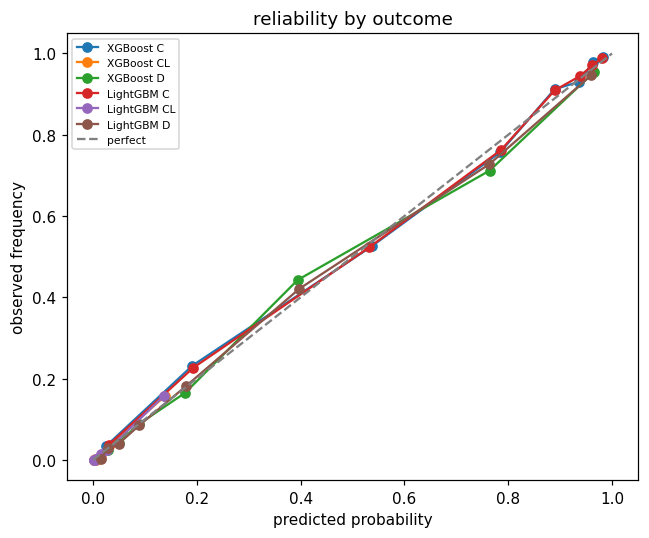

In [14]:
validation_rows = []
for name, pipeline in tuned.items():
    pipeline.fit(Xtr, ytr)
    plain = score_predictions(yv, pipeline.predict_proba(Xv))["log_loss"]
    validation_rows.append({"model": name, "method": "uncalibrated", "val_log_loss": plain})
    for method in ["sigmoid", "isotonic"]:
        adjusted = calibrate(pipeline, Xtr, ytr, method=method)
        loss = score_predictions(yv, adjusted.predict_proba(Xv))["log_loss"]
        validation_rows.append({"model": name, "method": method, "val_log_loss": loss})
validation = pd.DataFrame(validation_rows).sort_values("val_log_loss").reset_index(drop=True)
validation.to_csv(REPORTS_DIR / "final_evaluation" / "calibration_comparison.csv", index=False)
print(validation.to_string(index=False))
winner = validation.iloc[0]
best_name, best_method = winner["model"], winner["method"]
print("selected:", best_name, best_method)

fig, ax = plt.subplots(figsize=(6, 5))
for name, pipeline in tuned.items():
    proba = pipeline.predict_proba(Xv)
    for i, label in enumerate(CLASS_LABELS):
        true_frac, pred_frac = calibration_curve((yv_text == label).astype(int),
                                                 proba[:, i], n_bins=8, strategy="quantile")
        ax.plot(pred_frac, true_frac, marker="o", label=f"{name} {label}")
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.set_title("reliability by outcome")
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed frequency")
ax.legend(fontsize=7)
fig.savefig(FIGURES_DIR / "05_reliability.png", bbox_inches="tight")
plt.show()

## final model and diagnostics

Evaluate once on the untouched holdout, refit the chosen recipe on all labelled rows,
and save the fitted pipeline.

In [15]:
selected = clone(tuned[best_name])
selected.fit(Xtr, ytr)
eval_pipe = calibrate(selected, Xtr, ytr, method=best_method) if best_method != "uncalibrated" else selected
val_proba = eval_pipe.predict_proba(Xv)
val_metrics = score_predictions(yv, val_proba)
print("holdout metrics", val_metrics)

full_X = pd.concat([Xtr, Xv], ignore_index=True)
full_y = pd.concat([ytr, yv], ignore_index=True)
final_pipe = clone(tuned[best_name])
final_pipe.fit(full_X, full_y)
if best_method != "uncalibrated":
    final_pipe = calibrate(final_pipe, full_X, full_y, method=best_method)
joblib.dump(final_pipe, PIPELINE_PATH)
print("saved pipeline fitted on", len(full_X), "rows")

holdout metrics {'log_loss': 0.3723173137540401, 'accuracy': 0.8506666666666667, 'f1_macro': 0.6571151531310894}


saved pipeline fitted on 14999 rows


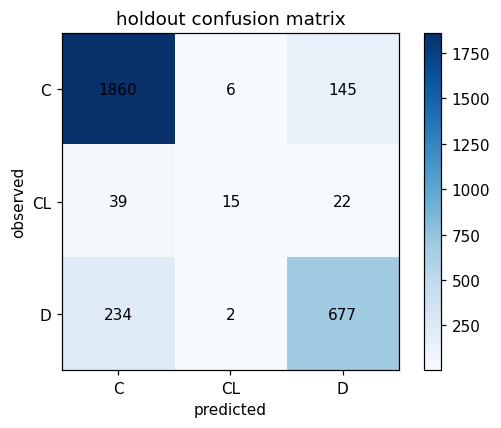

    feature  importance
  Bilirubin    0.116684
Prothrombin    0.060668
     N_Days    0.039475
        Age    0.036845
     Copper    0.015669
  Platelets    0.013699
       SGOT    0.013627
      Stage    0.011973


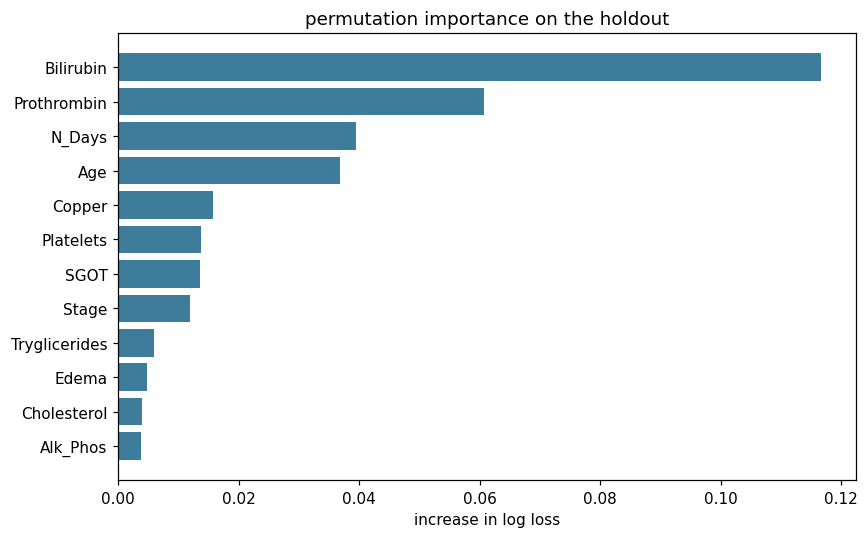

In [16]:
matrix = confusion_matrix(yv_text, np.asarray(CLASS_LABELS)[val_proba.argmax(axis=1)],
                          labels=CLASS_LABELS)
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(matrix, cmap="Blues")
ax.set_xticks(range(len(CLASS_LABELS)), CLASS_LABELS)
ax.set_yticks(range(len(CLASS_LABELS)), CLASS_LABELS)
for i in range(len(CLASS_LABELS)):
    for j in range(len(CLASS_LABELS)):
        ax.text(j, i, str(matrix[i, j]), ha="center", va="center")
ax.set_title("holdout confusion matrix")
ax.set_xlabel("predicted")
ax.set_ylabel("observed")
fig.colorbar(image, ax=ax)
fig.savefig(FIGURES_DIR / "05_confusion_calibration.png", bbox_inches="tight")
plt.show()

importance = permutation_importance(eval_pipe, Xv, yv, n_repeats=5,
                                    random_state=SEED, scoring="neg_log_loss")
importance_table = pd.DataFrame({"feature": Xv.columns,
                                 "importance": importance.importances_mean})
importance_table = importance_table.sort_values("importance", ascending=False)
importance_table.to_csv(MODELS_DIR / "feature_importance.csv", index=False)
print(importance_table.head(8).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
top_imp = importance_table.head(12).sort_values("importance")
ax.barh(top_imp["feature"], top_imp["importance"], color="#3D7C9B")
ax.set_title("permutation importance on the holdout")
ax.set_xlabel("increase in log loss")
fig.savefig(FIGURES_DIR / "05_feature_importance.png", bbox_inches="tight")
plt.show()

## submission and inference helpers

Write the competition file in the required format and verify that the saved pipeline
can be reloaded and used for single or batch predictions.

In [17]:
def build_submission(test_raw, template_frame, pipeline):
    # keep template order and normalize probabilities
    proba = pipeline.predict_proba(test_raw[RAW_FEATURES])
    values = {label: proba[:, CLASS_LABELS.index(label)] for label in CLASS_LABELS}
    result = template_frame[[ID_COLUMN]].copy()
    for label in CLASS_LABELS:
        result[f"Status_{label}"] = values[label]
    result = result[list(template_frame.columns)]
    numbers = result[PROB_COLUMNS].to_numpy(dtype=float)
    if not np.isfinite(numbers).all() or (numbers < 0).any():
        raise ValueError("invalid probabilities")
    result[PROB_COLUMNS] = numbers / numbers.sum(axis=1, keepdims=True)
    return result


def validate_submission(submission, template_frame):
    # explicit format checks
    numbers = submission[PROB_COLUMNS].to_numpy(dtype=float)
    checks = {
        "columns_exact": list(submission.columns) == list(template_frame.columns),
        "row_count": len(submission) == len(template_frame),
        "ids_preserved": submission[ID_COLUMN].equals(template_frame[ID_COLUMN]),
        "finite": bool(np.isfinite(numbers).all()),
        "non_negative": bool((numbers >= 0).all()),
        "normalized": bool(np.allclose(numbers.sum(axis=1), 1.0, atol=1e-6)),
    }
    checks["all_passed"] = all(checks.values())
    return checks


def load_artifacts():
    # reload the persisted pipeline
    if not PIPELINE_PATH.exists() or not METADATA_PATH.exists():
        raise FileNotFoundError("run the final model cell first")
    loaded = joblib.load(PIPELINE_PATH)
    with METADATA_PATH.open(encoding="utf-8") as handle:
        meta = json.load(handle)
    return loaded, meta


def validate_input(frame):
    # check uploaded columns
    missing = [column for column in RAW_FEATURES if column not in frame.columns]
    bad = []
    for column in RAW_NUMERIC:
        if column in frame.columns:
            values = frame[column].dropna()
            if len(values) and pd.to_numeric(values, errors="coerce").isna().all():
                bad.append(column)
    return missing + bad


def predict_dataframe(frame, pipeline):
    # score one or many patients
    problems = validate_input(frame)
    if problems:
        raise ValueError(f"invalid input columns: {problems}")
    values = frame[RAW_FEATURES].copy()
    for column in RAW_NUMERIC:
        values[column] = pd.to_numeric(values[column], errors="coerce")
    proba = pipeline.predict_proba(values)
    result = pd.DataFrame({f"Status_{label}": proba[:, CLASS_LABELS.index(label)]
                           for label in CLASS_LABELS})
    result[PROB_COLUMNS] = result[PROB_COLUMNS].div(result[PROB_COLUMNS].sum(axis=1), axis=0)
    result["predicted_status"] = np.asarray(CLASS_LABELS)[result[PROB_COLUMNS].to_numpy().argmax(axis=1)]
    result["confidence"] = result[PROB_COLUMNS].max(axis=1)
    return result


cv_row = bench[bench["model"] == best_name]
if "variant" in cv_row.columns:
    cv_row = cv_row[cv_row["variant"] == ("with_N_Days" if INCLUDE_N_DAYS else "without_N_Days")]
metadata = {
    "target": TARGET,
    "classes": CLASS_LABELS,
    "probability_columns": PROB_COLUMNS,
    "include_n_days": INCLUDE_N_DAYS,
    "n_labelled_rows": int(len(full_X)),
    "n_features_raw": len(RAW_FEATURES),
    "selected_model": best_name,
    "calibration_method": best_method,
    "cv_log_loss": float(cv_row["log_loss"].iloc[0]),
    "validation_log_loss": float(val_metrics["log_loss"]),
    "validation_accuracy": float(val_metrics["accuracy"]),
    "validation_f1_macro": float(val_metrics["f1_macro"]),
    "class_distribution": {key: int(value) for key, value in full_y.map(
        {i: label for label, i in code_map.items()}).value_counts().items()},
    "ndays_ablation": comparison.to_dict(orient="records"),
    "calibration_comparison": validation.to_dict(orient="records"),
    "seed": SEED,
}
with METADATA_PATH.open("w") as handle:
    json.dump(metadata, handle, indent=2, default=str)

submission = build_submission(test, template, final_pipe)
checks = validate_submission(submission, template)
print("submission checks", checks)
assert checks["all_passed"]
submission.to_csv(SUBMISSION_PATH, index=False)
print("saved", SUBMISSION_PATH, submission.shape)
print(submission.head().to_string(index=False))

reloaded, reloaded_meta = load_artifacts()
sample = test[RAW_FEATURES].head(3)
print(predict_dataframe(sample, reloaded).to_string(index=False))
print("reloaded model", reloaded_meta["selected_model"])

submission checks {'columns_exact': True, 'row_count': True, 'ids_preserved': True, 'finite': True, 'non_negative': True, 'normalized': True, 'all_passed': True}
saved /home/sabina/portfolio/cirrhosis/submission.csv (10000, 4)
   id  Status_C  Status_CL  Status_D
15000  0.310533   0.005942  0.683525
15001  0.867652   0.019233  0.113115
15002  0.797473   0.007255  0.195272
15003  0.984437   0.001609  0.013953
15004  0.319448   0.119523  0.561029
 Status_C  Status_CL  Status_D predicted_status  confidence
 0.310533   0.005942  0.683525                D    0.683525
 0.867652   0.019233  0.113115                C    0.867652
 0.797473   0.007255  0.195272                C    0.797473
reloaded model LightGBM


## notes

The days-in-study field improved cross validated log loss but acts as a stand-in for the
outcome. A real clinical tool should use the ablated contract. All estimates are statistical
results from synthetic data and are not medical diagnoses.